In [1]:
import os
import tempfile
import time
import urllib.request
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
MNIST_URL = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"
MNIST_PATH = os.path.join(tempfile.gettempdir(), "mnist.npz")

if not os.path.exists(MNIST_PATH):
    urllib.request.urlretrieve(MNIST_URL, MNIST_PATH)

with np.load(MNIST_PATH) as dataset:
    x_train_images = dataset["x_train"]
    y_train = dataset["y_train"].astype(np.int64)
    x_test_images = dataset["x_test"]
    y_test = dataset["y_test"].astype(np.int64)

print("Размер обучающей выборки изображений:", x_train_images.shape)
print("Размер обучающих меток:", y_train.shape)
print("Размер тестовой выборки изображений:", x_test_images.shape)
print("Размер тестовых меток:", y_test.shape)
print("Форма одного исходного изображения:", x_train_images[0].shape)

Размер обучающей выборки изображений: (60000, 28, 28)
Размер обучающих меток: (60000,)
Размер тестовой выборки изображений: (10000, 28, 28)
Размер тестовых меток: (10000,)
Форма одного исходного изображения: (28, 28)


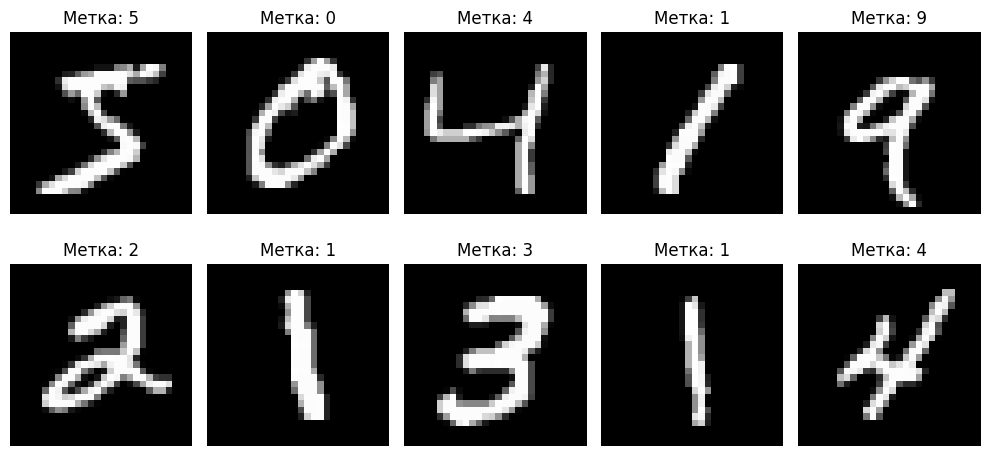

После преобразования обучающие изображения: (60000, 784)
После преобразования тестовые изображения: (10000, 784)
One-hot-метки обучения: (60000, 10)


In [2]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for index, axis in enumerate(axes.flat):
    axis.imshow(x_train_images[index], cmap="gray")
    axis.set_title(f"Метка: {y_train[index]}")
    axis.axis("off")
plt.tight_layout()
plt.show()

# Переводим пиксели в диапазон [0, 1]
x_train = x_train_images.reshape(x_train_images.shape[0], -1).astype(np.float32) / 255.0
x_test = x_test_images.reshape(x_test_images.shape[0], -1).astype(np.float32) / 255.0
input_size = x_train.shape[1]
num_classes = 10

def one_hot_encode(labels, classes):
    return np.eye(classes, dtype=np.float32)[labels]

y_train_one_hot = one_hot_encode(y_train, num_classes)
y_test_one_hot = one_hot_encode(y_test, num_classes)

print("После преобразования обучающие изображения:", x_train.shape)
print("После преобразования тестовые изображения:", x_test.shape)
print("One-hot-метки обучения:", y_train_one_hot.shape)

In [3]:
hidden_size = 300
learning_rate = 0.1
batch_size = 64
epochs = 20
weights_1 = (np.random.randn(input_size, hidden_size) * np.sqrt(2.0 / input_size)).astype(np.float32)
weights_2 = (np.random.randn(hidden_size, num_classes) * np.sqrt(1.0 / hidden_size)).astype(np.float32)
bias_1 = np.zeros((1, hidden_size), dtype=np.float32)
bias_2 = np.zeros((1, num_classes), dtype=np.float32)

print("W1:", weights_1.shape)
print("b1:", bias_1.shape)
print("W2:", weights_2.shape)
print("b2:", bias_2.shape)
print("Число обучаемых параметров:", weights_1.size + bias_1.size + weights_2.size + bias_2.size)

W1: (784, 300)
b1: (1, 300)
W2: (300, 10)
b2: (1, 10)
Число обучаемых параметров: 238510


In [4]:
def softmax(logits):
    shifted_logits = logits - np.max(logits, axis=1, keepdims=True)
    exponentials = np.exp(shifted_logits)
    return exponentials / np.sum(exponentials, axis=1, keepdims=True)


def forward_pass(inputs, w1, b1, w2, b2):
    z1 = inputs @ w1 + b1
    a1 = np.maximum(0.0, z1)  # ReLU
    z2 = a1 @ w2 + b2
    probabilities = softmax(z2)
    return z1, a1, probabilities

def cross_entropy(probabilities, correct_labels):
    epsilon = 1e-12
    return -np.sum(correct_labels * np.log(probabilities + epsilon)) / len(probabilities)


def predict(inputs, w1, b1, w2, b2, chunk_size=2048):
    predictions = np.empty(inputs.shape[0], dtype=np.int64)

    for start in range(0, inputs.shape[0], chunk_size):
        end = min(start + chunk_size, inputs.shape[0])
        _, _, probabilities = forward_pass(inputs[start:end], w1, b1, w2, b2)
        predictions[start:end] = np.argmax(probabilities, axis=1)
    return predictions

def evaluate(inputs, labels, labels_one_hot, w1, b1, w2, b2):
    total_correct = 0
    total_loss = 0.0
    chunk_size = 2048
    for start in range(0, inputs.shape[0], chunk_size):
        end = min(start + chunk_size, inputs.shape[0])
        _, _, probabilities = forward_pass(inputs[start:end], w1, b1, w2, b2)
        batch_predictions = np.argmax(probabilities, axis=1)
        total_correct += np.sum(batch_predictions == labels[start:end])
        total_loss += cross_entropy(probabilities, labels_one_hot[start:end]) * (end - start)

    accuracy = total_correct / inputs.shape[0]
    classification_error = 1.0 - accuracy
    mean_loss = total_loss / inputs.shape[0]
    return accuracy, classification_error, mean_loss

history = {"train_loss": [], "train_error": [], "epoch_time": []}

number_of_train_examples = x_train.shape[0]
for epoch in range(epochs):
    epoch_start = time.perf_counter()
    shuffled_indices = np.random.permutation(number_of_train_examples)

    for start in range(0, number_of_train_examples, batch_size):
        batch_indices = shuffled_indices[start:start + batch_size]
        inputs_batch = x_train[batch_indices]
        labels_batch = y_train_one_hot[batch_indices]
        current_batch_size = inputs_batch.shape[0]
        z1, a1, probabilities = forward_pass(inputs_batch, weights_1, bias_1, weights_2, bias_2)

        # Градиенты выходного слоя: dZ2 = (P - Y)
        dz2 = (probabilities - labels_batch) / current_batch_size
        d_weights_2 = a1.T @ dz2
        d_bias_2 = np.sum(dz2, axis=0, keepdims=True)

        # Передаём ошибку в скрытый слой и учитываем производную ReLU.
        da1 = dz2 @ weights_2.T
        dz1 = da1 * (z1 > 0.0)
        d_weights_1 = inputs_batch.T @ dz1
        d_bias_1 = np.sum(dz1, axis=0, keepdims=True)

        weights_1 -= learning_rate * d_weights_1
        bias_1 -= learning_rate * d_bias_1
        weights_2 -= learning_rate * d_weights_2
        bias_2 -= learning_rate * d_bias_2

    train_accuracy, train_error, train_loss = evaluate(x_train, y_train, y_train_one_hot, weights_1, bias_1, weights_2, bias_2)
    epoch_seconds = time.perf_counter() - epoch_start

    history["train_loss"].append(train_loss)
    history["train_error"].append(train_error)
    history["epoch_time"].append(epoch_seconds)

    print(f"Эпоха {epoch + 1:02d}/{epochs} | "f"ошибка классификации: {train_error * 100:.2f}% | "f"точность: {train_accuracy * 100:.2f}% | "
          f"кросс-энтропия: {train_loss:.4f} | "f"время: {epoch_seconds:.2f} с")

Эпоха 01/20 | ошибка классификации: 6.83% | точность: 93.17% | кросс-энтропия: 0.2419 | время: 8.87 с
Эпоха 02/20 | ошибка классификации: 4.56% | точность: 95.44% | кросс-энтропия: 0.1607 | время: 2.50 с
Эпоха 03/20 | ошибка классификации: 3.40% | точность: 96.60% | кросс-энтропия: 0.1232 | время: 2.98 с
Эпоха 04/20 | ошибка классификации: 2.71% | точность: 97.29% | кросс-энтропия: 0.0985 | время: 4.76 с
Эпоха 05/20 | ошибка классификации: 2.58% | точность: 97.42% | кросс-энтропия: 0.0904 | время: 2.46 с
Эпоха 06/20 | ошибка классификации: 1.93% | точность: 98.07% | кросс-энтропия: 0.0714 | время: 2.47 с
Эпоха 07/20 | ошибка классификации: 1.69% | точность: 98.31% | кросс-энтропия: 0.0636 | время: 2.43 с
Эпоха 08/20 | ошибка классификации: 1.46% | точность: 98.54% | кросс-энтропия: 0.0564 | время: 5.41 с
Эпоха 09/20 | ошибка классификации: 1.25% | точность: 98.75% | кросс-энтропия: 0.0486 | время: 2.45 с
Эпоха 10/20 | ошибка классификации: 1.15% | точность: 98.85% | кросс-энтропия: 0.0

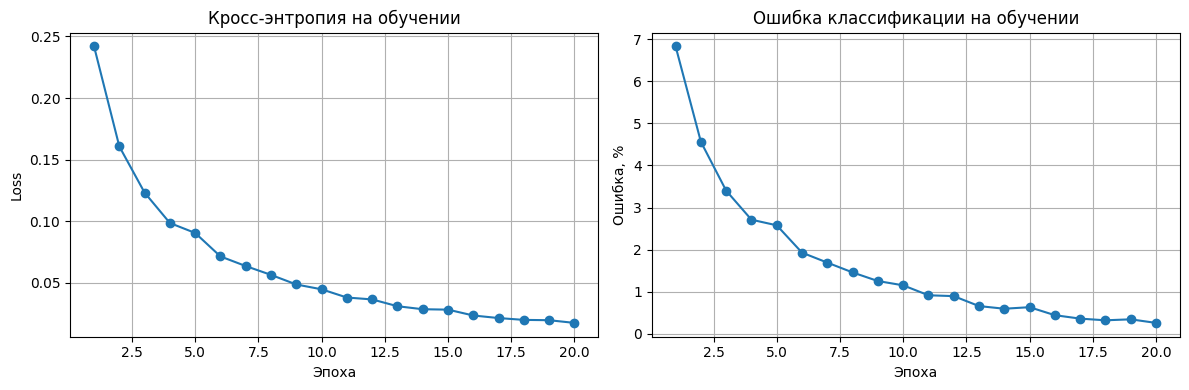

Среднее время эпохи: 3.46 с
Общее время обучения вместе с оценкой train: 69.11 с


In [5]:
epoch_numbers = np.arange(1, epochs + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epoch_numbers, history["train_loss"], marker="o")
axes[0].set_title("Кросс-энтропия на обучении")
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("Loss")
axes[0].grid(True)

axes[1].plot(epoch_numbers, np.array(history["train_error"]) * 100, marker="o")
axes[1].set_title("Ошибка классификации на обучении")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("Ошибка, %")
axes[1].grid(True)
plt.tight_layout()
plt.show()

print(f"Среднее время эпохи: {np.mean(history['epoch_time']):.2f} с")
print(f"Общее время обучения вместе с оценкой train: {np.sum(history['epoch_time']):.2f} с")

In [6]:
test_accuracy, test_error, test_loss = evaluate(x_test, y_test, y_test_one_hot, weights_1, bias_1, weights_2, bias_2)

print(f"Точность на тестовой выборке: {test_accuracy * 100:.2f}%")
print(f"Ошибка классификации на тестовой выборке: {test_error * 100:.2f}%")
print(f"Кросс-энтропия на тестовой выборке: {test_loss:.4f}")

Точность на тестовой выборке: 98.00%
Ошибка классификации на тестовой выборке: 2.00%
Кросс-энтропия на тестовой выборке: 0.0624
